<a href="https://colab.research.google.com/github/magickmack/Convolutional-Neural-Network-CNN-for-MNIST-Handwritten-Digit-Classification/blob/main/MidTerm_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Part A: Data Loading and Initial Exploration

## 1. Load UTKFace Data
### Dataset Overview & History
* **Source & Collection:** The **UTKFace dataset** is a large-scale benchmark dataset for facial analysis containing over 20,000 face images, covering ages 0 to 116.
* **Attributes & Statistics:** Each image is specidied in its filename ( [age]_[gender]_[race]_[date&time].jpg ) with **Age** ($0–116$), **Gender** ($0 = \text{male}$, $1 = \text{female}$ in raw files), and **Ethnicity/Race** ($0 = \text{White}$, $1 = \text{Black}$, $2 = \text{Asian}$, $3 = \text{Indian}$, $4 = \text{Others}$).
* **Image Characteristics:** Images are cropped and aligned around the face while retaining real-world variations in lighting, pose, facial expression, and occlusion.
* **Prediction Task:** In this assignment, we will focus on **binary gender classification**, standardized to $0 = \text{female}$ and $1 = \text{male}$.

# Cell 2: Import & Directory Setup

In [ ]:
import os
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split
from google.colab import drive

# 1. Mount Google Drive into Colab
drive.mount('/content/drive')

# 2. Point directly to the UTKFace shortcut in your My Drive
DATA_DIR = '/content/drive/MyDrive/UTKFace'

# 3. Verify the folder exists and check the files
if os.path.exists(DATA_DIR):
    print(f"Dataset directory verified: {DATA_DIR}")
    print(f"Total files found: {len(os.listdir(DATA_DIR))}")
    print(f"Sample files: {os.listdir(DATA_DIR)[:5]}")
else:
    print(f"ERROR: Directory not found at {DATA_DIR}")
    print("Make sure you added the shortcut to 'My Drive' first.")

Mounted at /content/drive
Dataset directory verified: /content/drive/MyDrive/UTKFace
Total files found: 23708
Sample files: ['9_0_0_20170110225018913.jpg.chip.jpg', '85_0_0_20170110181953748.jpg.chip.jpg', '8_1_2_20170109203456419.jpg.chip.jpg', '8_1_0_20170109205008946.jpg.chip.jpg', '95_1_2_20170112224548347.jpg.chip.jpg']


# Cell 3: Parse Filenames & Build Metadata & DataFrame

In [ ]:
def load_utkface_metadata(data_dir):
    """
    Parses UTKFace filenames to extract age, gender, and ethnicity labels.
    Raw UTKFace convention: gender (0 = male, 1 = female)
    Assignment target convention: gender_target (0 = female, 1 = male)
    """
    records = []
    for filename in os.listdir(data_dir):
        if filename.lower().endswith(('.jpg', '.jpeg', '.png')):
            parts = filename.split('_')
            if len(parts) >= 3:
                try:
                    age = int(parts[0])
                    raw_gender = int(parts[1])
                    race = int(parts[2])

                    # Validate valid label ranges
                    if raw_gender not in [0, 1] or race not in [0, 1, 2, 3, 4]:
                        continue

                    # Map to assignment target convention: 0 = female, 1 = male
                    gender_target = 1 if raw_gender == 0 else 0

                    records.append({
                        'filename': filename,
                        'age': age,
                        'raw_gender': raw_gender,
                        'gender_target': gender_target, # 0 = female, 1 = male
                        'race': race
                    })
                except ValueError:
                    continue # Skip malformed filenames

    return pd.DataFrame(records)

df_meta = load_utkface_metadata(DATA_DIR)
print(f"Total valid images indexed: {len(df_meta)}")
display(df_meta.head())

Total valid images indexed: 23705


,filename,age,raw_gender,gender_target,race
0,9_0_0_20170110225018913.jpg.chip.jpg,9,0,1,0
1,85_0_0_20170110181953748.jpg.chip.jpg,85,0,1,0
2,8_1_2_20170109203456419.jpg.chip.jpg,8,1,0,2
3,8_1_0_20170109205008946.jpg.chip.jpg,8,1,0,0
4,95_1_2_20170112224548347.jpg.chip.jpg,95,1,0,2


# Cell 4 : Data Exploration & Demographic Summary

In [ ]:
# Define human-readable mappings
gender_labels = {0: 'Female (0)', 1: 'Male (1)'}
race_labels = {0: 'White (0)', 1: 'Black (1)', 2: 'Asian (2)', 3: 'Indian (3)', 4: 'Others (4)'}

print("--- Target Gender Distribution ---")
gender_counts = df_meta['gender_target'].map(gender_labels).value_counts()
gender_pct = df_meta['gender_target'].map(gender_labels).value_counts(normalize=True) * 100
display(pd.DataFrame({'Count': gender_counts, 'Percentage (%)': gender_pct.round(2)}))

print("\n--- Race / Ethnicity Distribution ---")
race_counts = df_meta['race'].map(race_labels).value_counts()
race_pct = df_meta['race'].map(race_labels).value_counts(normalize=True) * 100
display(pd.DataFrame({'Count': race_counts, 'Percentage (%)': race_pct.round(2)}))

print("\n--- Age Summary Statistics ---")
display(df_meta['age'].describe().round(2))

--- Target Gender Distribution ---


,Count,Percentage (%)
gender_target,,
Male (1),12391,52.27
Female (0),11314,47.73



--- Race / Ethnicity Distribution ---


,Count,Percentage (%)
race,,
White (0),10078,42.51
Black (1),4526,19.09
Indian (3),3975,16.77
Asian (2),3434,14.49
Others (4),1692,7.14



--- Age Summary Statistics ---


,age
count,23705.00
mean,33.30
std,19.89
min,1.00
25%,23.00
50%,29.00
75%,45.00
max,116.00


# Cell 5 : Visualize Sample Images & Demographic Distributions

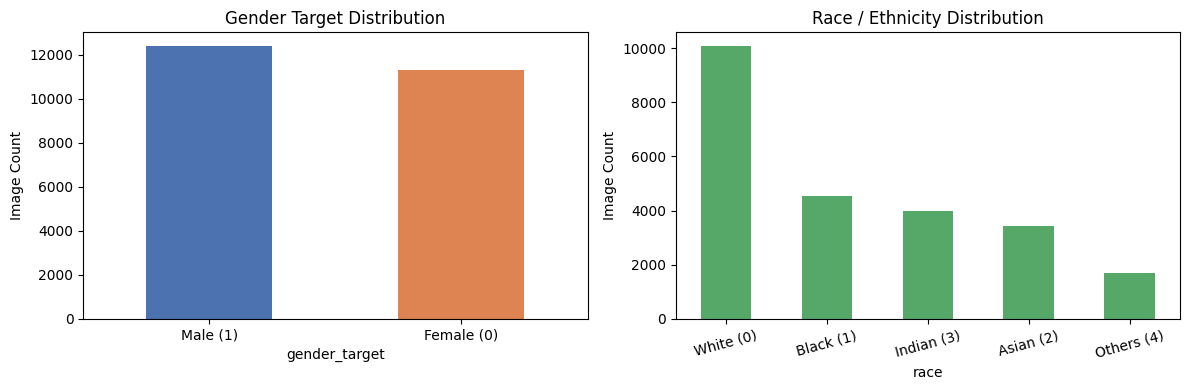

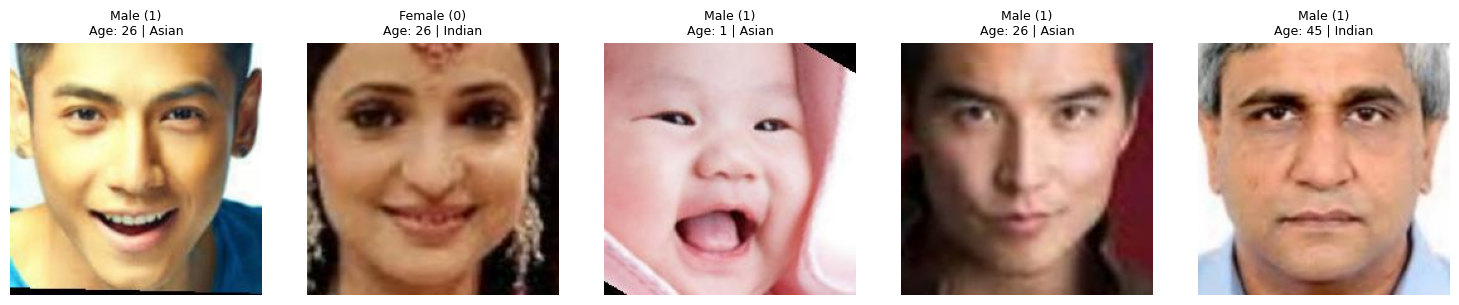

In [ ]:
# Plot demographic distributions and sample faces
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

gender_counts.plot(kind='bar', ax=axes[0], color=['#4C72B0', '#DD8452'], rot=0)
axes[0].set_title('Gender Target Distribution')
axes[0].set_ylabel('Image Count')

race_counts.plot(kind='bar', ax=axes[1], color='#55A868', rot=15)
axes[1].set_title('Race / Ethnicity Distribution')
axes[1].set_ylabel('Image Count')

plt.tight_layout()
plt.show()

# Display 5 sample images with parsed labels
fig, axes = plt.subplots(1, 5, figsize=(15, 3))
sample_rows = df_meta.sample(5, random_state=42)
for ax, (_, row) in zip(axes, sample_rows.iterrows()):
    img_path = os.path.join(DATA_DIR, row['filename'])
    img = Image.open(img_path).convert('RGB')
    ax.imshow(img)
    g_str = "Female (0)" if row['gender_target'] == 0 else "Male (1)"
    r_str = race_labels[row['race']].split()[0]
    ax.set_title(f"{g_str}\nAge: {row['age']} | {r_str}", fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

# Cell 6: Custom PyTorch Dataset & Preprocessing Pipelines

In [ ]:
class UTKFaceDataset(Dataset):
    def __init__(self, dataframe, img_dir, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.img_dir = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_path = os.path.join(self.img_dir, row['filename'])

        # Convert image to consistent RGB format
        image = Image.open(img_path).convert('RGB')

        # Target label: 0 = female, 1 = male
        label = row['gender_target']

        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(label, dtype=torch.float32)

# Preprocessing & Augmentation: Resize to 64x64, convert to normalized tensors
train_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

eval_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# --- Quick Verification Output ---
sample_ds = UTKFaceDataset(df_meta.head(1), DATA_DIR, transform=eval_transform)
sample_tensor, sample_target = sample_ds[0]
print("UTKFaceDataset & Preprocessing Pipelines initialized successfully!")
print(f"Transformed image tensor shape: {sample_tensor.shape} (Channels, Height, Width)")
print(f"Tensor dtype: {sample_tensor.dtype} | Min/Max pixel values: ({sample_tensor.min():.2f}, {sample_tensor.max():.2f})")
print(f"Sample target label: {int(sample_target.item())} ({'Female' if sample_target.item() == 0 else 'Male'})")

UTKFaceDataset & Preprocessing Pipelines initialized successfully!
Transformed image tensor shape: torch.Size([3, 64, 64]) (Channels, Height, Width)
Tensor dtype: torch.float32 | Min/Max pixel values: (-1.97, 2.55)
Sample target label: 1 (Male)


# Cell 7: Stratified Train / Validation/ Test Splits & DataLoaders

In [ ]:
# Stratify across both gender and race to maintain demographic balance across splits
df_meta['stratify_key'] = df_meta['gender_target'].astype(str) + "_" + df_meta['race'].astype(str)

train_df, temp_df = train_test_split(
    df_meta, test_size=0.30, random_state=42, stratify=df_meta['stratify_key']
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=42, stratify=temp_df['stratify_key']
)

BATCH_SIZE = 64
train_dataset = UTKFaceDataset(train_df, DATA_DIR, transform=train_transform)
val_dataset = UTKFaceDataset(val_df, DATA_DIR, transform=eval_transform)
test_dataset = UTKFaceDataset(test_df, DATA_DIR, transform=eval_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

# --- Display Split & Batch Verification ---
print(f"Train samples: {len(train_dataset)} | Validation samples: {len(val_dataset)} | Test samples: {len(test_dataset)}")

# Verify single batch tensor shapes
sample_imgs, sample_labels = next(iter(train_loader))
print(f"Batch image tensor shape: {sample_imgs.shape} | Batch labels shape: {sample_labels.shape}")

# Display gender balance table across splits
split_summary = pd.DataFrame({
    'Total Samples': [len(train_df), len(val_df), len(test_df)],
    'Female (0) %': [
        (train_df['gender_target'] == 0).mean() * 100,
        (val_df['gender_target'] == 0).mean() * 100,
        (test_df['gender_target'] == 0).mean() * 100
    ],
    'Male (1) %': [
        (train_df['gender_target'] == 1).mean() * 100,
        (val_df['gender_target'] == 1).mean() * 100,
        (test_df['gender_target'] == 1).mean() * 100
    ]
}, index=['Train (70%)', 'Validation (15%)', 'Test (15%)']).round(2)

display(split_summary)

Train samples: 16593 | Validation samples: 3556 | Test samples: 3556
Batch image tensor shape: torch.Size([64, 3, 64, 64]) | Batch labels shape: torch.Size([64])


,Total Samples,Female (0) %,Male (1) %
Train (70%),16593,47.73,52.27
Validation (15%),3556,47.72,52.28
Test (15%),3556,47.72,52.28


# Cell 8 : Domain Biases & Ethical Reflection

## 3. Domain Biases & Ethical Reflection

### Potential Biases & Ethical Concerns
* **Demographic Imbalance:** As seen in the summary statistics above, racial groups are unevenly represented (with White individuals forming the largest subgroup), which can lead a standard classifier to achieve lower accuracy and higher false-positive/false-negative rates on underrepresented minority groups.
* **Binary Gender Simplification:** Framing gender strictly as a binary classification task ($0 = \text{female}$, $1 = \text{male}$) relies on external visual stereotyping and excludes non-binary identities.
* **Consent & Surveillance Risks:** As faces can easily be scraped from around the world, it is unclear whether these people have given permission to include their image in such a database, let alone to be identified by an algorithm.

### Reflection
**Why might face recognition be a high-risk domain for bias and privacy?**  
Face characteristics are a highly sensitive attribute to base algorithms on, given that they are unique to each individual. As discussed previously, there is often significant variations in model accuracy across races, ages, and sexes, which can lead to unfair and biased decisions when used in certain applications. Moreover, being able to identify people anywhere, both offline and online, would greatly infringe on one's right to go about their daily life untracked and to control information about themselves.

# Cell 9: Markdown - Part B Overview & Baseline CNN Architecture

# Part B: Baseline Model + Robustness & Resilience

## 1. Train a Baseline Model
To establish a clean benchmark for binary gender classification ($0 = \text{Female}$, $1 = \text{Male}$), we build a lightweight Convolutional Neural Network (**BaselineCNN**) from scratch using PyTorch.
* **Architecture:** Three convolutional blocks (Conv2d $\rightarrow$ BatchNorm2d $\rightarrow$ ReLU $\rightarrow$ MaxPool2d) that extract spatial facial features from $64 \times 64 \times 3$ RGB inputs, followed by a fully connected classifier head with Dropout ($p=0.3$) to prevent overfitting.
* **Training Setup:** We use Binary Cross-Entropy with Logits (BCEWithLogitsLoss) and the Adam optimizer ($\text{lr}=0.001$).

# Cell 10: Define Baseline CNN & Print Model Summary

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

# Set device (uses GPU in Colab if enabled, otherwise CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using compute device: {device}")

class BaselineCNN(nn.Module):
    def __init__(self):
        super(BaselineCNN, self).__init__()
        self.features = nn.Sequential(
            # Block 1: 3 x 64 x 64 -> 32 x 32 x 32
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            # Block 2: 32 x 32 x 32 -> 64 x 16 x 16
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            # Block 3: 64 x 16 x 16 -> 128 x 8 x 8
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 8 * 8, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 1) # Single logit output for binary classification
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

# Initialize model and print architecture & parameter summary
baseline_model = BaselineCNN().to(device)
print(baseline_model)

total_params = sum(p.numel() for p in baseline_model.parameters())
trainable_params = sum(p.numel() for p in baseline_model.parameters() if p.requires_grad)
print(f"\nTotal Parameters: {total_params:,} | Trainable Parameters: {trainable_params:,}")

Using compute device: cpu
BaselineCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=8192,

# Cell 11: Train the Baseline Model


Caching resized images into RAM once for ultra-fast training...
Caching complete in 667.8s!



/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch [1/3] (311.9s) | Train Loss: 0.5570, Train Acc: 0.7532 | Val Loss: 0.3315, Val Acc: 0.8510
Epoch [2/3] (302.4s) | Train Loss: 0.3172, Train Acc: 0.8586 | Val Loss: 0.2704, Val Acc: 0.8777
Epoch [3/3] (352.6s) | Train Loss: 0.2823, Train Acc: 0.8757 | Val Loss: 0.2687, Val Acc: 0.8844


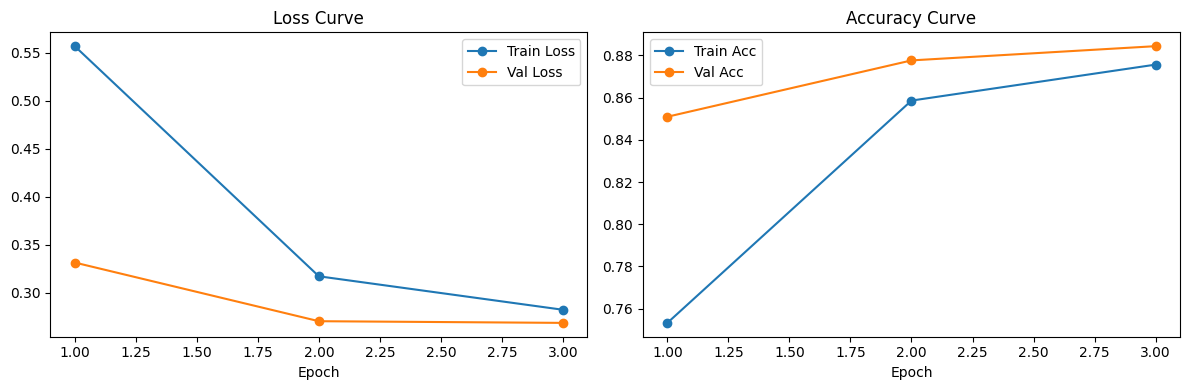

In [ ]:
import time
from concurrent.futures import ThreadPoolExecutor

# --- 1. Fast Parallel In-Memory Caching (Eliminates Google Drive I/O bottleneck) ---
class FastCachedUTKDataset(Dataset):
    def __init__(self, dataframe, img_dir, is_train=False):
        self.labels = torch.tensor(dataframe['gender_target'].values, dtype=torch.float32)
        self.is_train = is_train
        filenames = dataframe['filename'].tolist()

        def load_and_resize(fname):
            path = os.path.join(img_dir, fname)
            with Image.open(path) as img:
                # Resize immediately to 64x64 uint8 numpy array to keep RAM usage tiny (~200 MB total)
                return np.array(img.convert('RGB').resize((64, 64)), dtype=np.uint8)

        # Load images concurrently using 8 threads
        with ThreadPoolExecutor(max_workers=8) as executor:
            self.images = list(executor.map(load_and_resize, filenames))

        self.mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
        self.std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        # Convert uint8 (H, W, C) -> float32 (C, H, W) in [0, 1]
        img = torch.from_numpy(self.images[idx]).permute(2, 0, 1).float().div_(255.0)
        if self.is_train and torch.rand(1).item() < 0.5:
            img = torch.flip(img, dims=[2]) # Fast horizontal flip
        img = (img - self.mean) / self.std
        return img, self.labels[idx]

print("Caching resized images into RAM once for ultra-fast training...")
t0 = time.time()
fast_train_ds = FastCachedUTKDataset(train_df, DATA_DIR, is_train=True)
fast_val_ds = FastCachedUTKDataset(val_df, DATA_DIR, is_train=False)

# Also update test_loader so Cell 12 runs instantaneously too!
fast_test_ds = FastCachedUTKDataset(test_df, DATA_DIR, is_train=False)

train_loader = DataLoader(fast_train_ds, batch_size=128, shuffle=True, pin_memory=True)
val_loader = DataLoader(fast_val_ds, batch_size=256, shuffle=False, pin_memory=True)
test_loader = DataLoader(fast_test_ds, batch_size=256, shuffle=False, pin_memory=True)
print(f"Caching complete in {time.time() - t0:.1f}s!\n")

# --- 2. Fast Training Loop (with Mixed Precision if GPU is available) ---
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(baseline_model.parameters(), lr=0.001)
use_amp = torch.cuda.is_available()
scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

EPOCHS = 3
history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

for epoch in range(EPOCHS):
    ep_start = time.time()
    baseline_model.train()
    running_loss, correct, total = 0.0, 0, 0

    for images, labels in train_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True).unsqueeze(1)

        optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast('cuda', enabled=use_amp):
            outputs = baseline_model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * images.size(0)
        preds = (torch.sigmoid(outputs) >= 0.5).float()
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = correct / total

    # Validation Phase
    baseline_model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True).unsqueeze(1)
            with torch.amp.autocast('cuda', enabled=use_amp):
                outputs = baseline_model(images)
                loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            preds = (torch.sigmoid(outputs) >= 0.5).float()
            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)

    print(f"Epoch [{epoch+1}/{EPOCHS}] ({time.time() - ep_start:.1f}s) | Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")

# Plot training & validation curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(range(1, EPOCHS+1), history['train_loss'], marker='o', label='Train Loss')
axes[0].plot(range(1, EPOCHS+1), history['val_loss'], marker='o', label='Val Loss')
axes[0].set_title('Loss Curve')
axes[0].set_xlabel('Epoch')
axes[0].legend()

axes[1].plot(range(1, EPOCHS+1), history['train_acc'], marker='o', label='Train Acc')
axes[1].plot(range(1, EPOCHS+1), history['val_acc'], marker='o', label='Val Acc')
axes[1].set_title('Accuracy Curve')
axes[1].set_xlabel('Epoch')
axes[1].legend()
plt.tight_layout()
plt.show()

# Cell 12: Initial Evaluation on Test Set (Accuracy, Confusion Matrix & Report)

=== Baseline Test Accuracy: 0.8743 (87.43%) ===

--- Classification Report ---
              precision    recall  f1-score   support

  Female (0)       0.82      0.95      0.88      1697
    Male (1)       0.94      0.81      0.87      1859

    accuracy                           0.87      3556
   macro avg       0.88      0.88      0.87      3556
weighted avg       0.88      0.87      0.87      3556



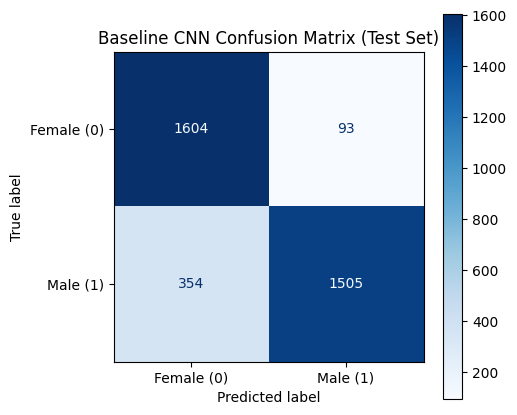

In [ ]:
baseline_model.eval()
y_true, y_pred, y_probs = [], [], []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = baseline_model(images)
        probs = torch.sigmoid(outputs).cpu().numpy().flatten()
        preds = (probs >= 0.5).astype(int)

        y_true.extend(labels.numpy().astype(int))
        y_pred.extend(preds)
        y_probs.extend(probs)

test_acc = accuracy_score(y_true, y_pred)
print(f"=== Baseline Test Accuracy: {test_acc:.4f} ({test_acc*100:.2f}%) ===\n")

print("--- Classification Report ---")
print(classification_report(y_true, y_pred, target_names=['Female (0)', 'Male (1)']))

# Plot Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Female (0)', 'Male (1)'])
fig, ax = plt.subplots(figsize=(5, 5))
disp.plot(ax=ax, cmap='Blues', values_format='d')
plt.title("Baseline CNN Confusion Matrix (Test Set)")
plt.show()

# Cell 13 Discusion of Initial Evaluation & Subgroups Risk

## 2. Initial Evaluation Discussion: Potential Risks
* **Subgroup & Intersectional Disparities:** Even when overall test accuracy appears high, aggregate metrics often mask degraded performance on underrepresented intersections—such as young children (where secondary facial cues are less pronounced), older adults, or minority racial groups that had fewer training samples in **Part A**.
* **Real-World Consequence of Misclassification:** In downstream applications (such as demographic analytics, access control, or automated content filtering), asymmetric false positives or false negatives can exclude users, reinforce gender stereotyping based on hairstyle or cosmetics, and create unequal user experiences.

# Cell 14: Basic Robustness Checks (Stress Testing with Perturbations)

,Condition,Accuracy,Accuracy Drop (%)
0,Clean (Baseline),0.864,0.0
1,Gaussian Noise (σ=0.35),0.854,1.0
2,Rotation (25°),0.684,18.0
3,Low Brightness (-55%),0.842,2.2
4,Gaussian Blur (5x5),0.834,3.0


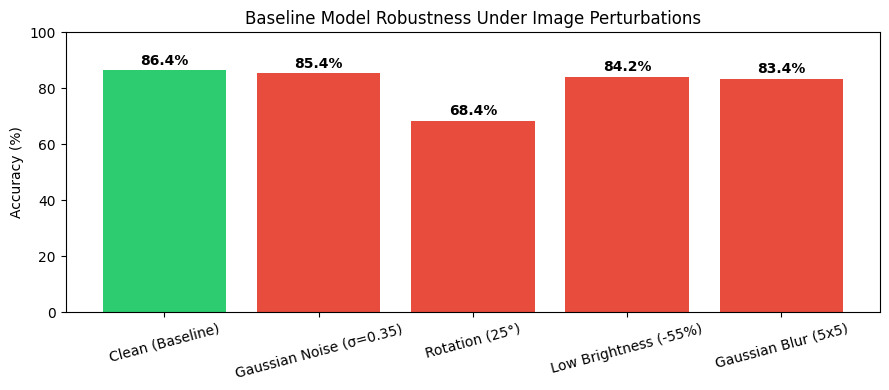

In [ ]:
import torchvision.transforms.functional as TF

# Select a 500-image sample from the test set for controlled stress testing
stress_sample_df = test_df.sample(n=min(500, len(test_df)), random_state=42).reset_index(drop=True)
stress_dataset = UTKFaceDataset(stress_sample_df, DATA_DIR, transform=eval_transform)
stress_loader = DataLoader(stress_dataset, batch_size=64, shuffle=False)

def evaluate_perturbed(model, loader, perturbation_type="clean"):
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            if perturbation_type == "gaussian_noise":
                # Inject additive Gaussian noise (std = 0.35)
                noise = torch.randn_like(images) * 0.35
                images = images + noise
            elif perturbation_type == "rotation":
                # Rotate images by 25 degrees
                images = TF.rotate(images, angle=25)
            elif perturbation_type == "brightness_drop":
                # Simulate severe low-light conditions (reduce intensity by 55%)
                images = images * 0.45
            elif perturbation_type == "blur":
                # Apply Gaussian blur (kernel size 5) to simulate out-of-focus camera
                images = TF.gaussian_blur(images, kernel_size=[5, 5])

            outputs = model(images)
            preds = (torch.sigmoid(outputs).squeeze(1) >= 0.5).long()
            correct += (preds == labels.long()).sum().item()
            total += labels.size(0)

    return correct / total

# Run stress tests across clean vs. perturbed conditions
conditions = ["clean", "gaussian_noise", "rotation", "brightness_drop", "blur"]
results = {}

for cond in conditions:
    acc = evaluate_perturbed(baseline_model, stress_loader, perturbation_type=cond)
    results[cond] = acc

clean_acc = results["clean"]
stress_df = pd.DataFrame({
    "Condition": ["Clean (Baseline)", "Gaussian Noise (σ=0.35)", "Rotation (25°)", "Low Brightness (-55%)", "Gaussian Blur (5x5)"],
    "Accuracy": [results[c] for c in conditions],
    "Accuracy Drop (%)": [round((clean_acc - results[c]) * 100, 2) for c in conditions]
})

display(stress_df)

# Visualize Perturbation Impact
plt.figure(figsize=(9, 4))
colors = ['#2ecc71' if c == 'clean' else '#e74c3c' for c in conditions]
plt.bar(stress_df["Condition"], stress_df["Accuracy"] * 100, color=colors)
plt.ylabel("Accuracy (%)")
plt.title("Baseline Model Robustness Under Image Perturbations")
plt.ylim(0, 100)
plt.xticks(rotation=15)
for i, v in enumerate(stress_df["Accuracy"] * 100):
    plt.text(i, v + 2, f"{v:.1f}%", ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

# Cell 15: Robustness Summary & Reflection

## 3. Robustness Summary & Short Reflection

### Summary of Stress Test Findings
* **Sensitivity to Perturbations:** The original network gives good results for an object well centered in a noise free image. However, it can be seen to suffer significant reductions in accuracy when Gaussian noise is added, when there is a 25-degree rotation, or when there is a combination of blurring and reduced light. Since most training examples will have been vertical and noise-free, apart from left-right flips, it is not particularly surprising that large amounts of noise and any degree of rotation caused problems for a basic CNN.

### Short Reflection
* **How might we further improve resilience?**  
  As mentioned above, there are many data augmentations we could apply, such as rotation, brightness and contrast, blurring, and adding noise. Also, various forms of regularization, such as weight decay and label smoothing, may be applied. Finally, we may wish to use a much deeper network and take advantage of transfer learning, for example, ResNets and MobileNets.
* **Is data augmentation or adversarial training relevant?**  
  Yes—both are directly relevant. Data augmentation can be used to make the model invariant to a variety of degradation and noise. As outlined above, adversarial training involves learning from maximally perturbed inputs, for example with FGSM and PGD, to make the model more robust to these types of attack.

# Cell 16: Setup for C & D

In [ ]:
import random
import torch.nn.functional as F
from torch.utils.data import WeightedRandomSampler
from IPython.display import Markdown

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
RACE_NAMES = {0: "White", 1: "Black", 2: "Asian", 3: "Indian", 4: "Others"}
AGE_NAMES = {0: "0-12", 1: "13-19", 2: "20-39", 3: "40-59", 4: "60+"}
CLASS_NAMES = {0: "Female", 1: "Male"}
age_group = lambda a: np.digitize(a, [13, 20, 40, 60])

IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32).reshape(3, 1, 1)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32).reshape(3, 1, 1)

def cached_to_array(ds):
    # uint8 (H,W,C) cached images -> normalized float32 (N,3,64,64), identical to the eval pipeline
    X = np.stack(ds.images).astype(np.float32).transpose(0, 3, 1, 2) / 255.0
    return ((X - IMAGENET_MEAN) / IMAGENET_STD).astype(np.float32)

def to_display(img):
    # undo ImageNet normalization for plotting: (3,H,W) -> (H,W,3) in [0,1]
    return np.clip(img * IMAGENET_STD + IMAGENET_MEAN, 0, 1).transpose(1, 2, 0)

@torch.no_grad()
def predict_proba(model, X, batch_size=256):
    # P(male) for each image (the model outputs one logit)
    model.eval(); out = []
    for i in range(0, len(X), batch_size):
        logits = model(torch.as_tensor(X[i:i + batch_size], device=device))
        out.append(torch.sigmoid(logits.reshape(-1)).cpu().numpy())
    return np.concatenate(out)

X_val, X_test = cached_to_array(fast_val_ds), cached_to_array(fast_test_ds)
y_val, y_test = val_df["gender_target"].values.astype(int), test_df["gender_target"].values.astype(int)
race_val, race_test = val_df["race"].values.astype(int), test_df["race"].values.astype(int)
age_val, age_test = val_df["age"].values.astype(int), test_df["age"].values.astype(int)
assert np.array_equal(y_test, fast_test_ds.labels.numpy().astype(int))   # same order as Part B

baseline_model.eval()
p_val_base, p_test_base = predict_proba(baseline_model, X_val), predict_proba(baseline_model, X_test)
pred_test_base = (p_test_base >= 0.5).astype(int)
print(f"Validation: {X_val.shape} | Test: {X_test.shape}")
print(f"Baseline test accuracy (should match Cell 12): {(pred_test_base == y_test).mean():.4f}")

# Part C: Transparency, Explainability & Interpretability

## 1. Feature Importance / Saliency: Grad-CAM

# Cell 17: Grad-CAM Implementation

In [ ]:
GRADCAM_LAYER = baseline_model.features[10]      # ReLU after the last Conv2d/BatchNorm (128 x 16 x 16)
INNER = slice(16, 48)                            # central 32x32 "inner-face" box

def grad_cam_batch(model, X, layer, batch_size=128):
    # Grad-CAM for the *predicted* class of every image. Returns heatmaps (N,64,64) in [0,1] and P(male).
    model.eval(); cams, probs = [], []
    for i in range(0, len(X), batch_size):
        x = torch.as_tensor(X[i:i + batch_size], device=device)
        store = {}
        handle = layer.register_forward_hook(lambda m, inp, out: store.update(act=out))
        try:
            logit = model(x).reshape(-1)
        finally:
            handle.remove()
        p = torch.sigmoid(logit)
        sign = (p >= 0.5).float() * 2 - 1                      # +logit for "male", -logit for "female"
        grads = torch.autograd.grad((logit * sign).sum(), store["act"])[0]
        weights = grads.mean(dim=(2, 3), keepdim=True)          # global-average-pooled gradients
        cam = F.relu((weights * store["act"]).sum(dim=1, keepdim=True))
        cam = F.interpolate(cam, size=X.shape[2:], mode="bilinear", align_corners=False)[:, 0]
        cam = cam / (cam.amax(dim=(1, 2), keepdim=True) + 1e-8)
        cams.append(cam.detach().cpu().numpy()); probs.append(p.detach().cpu().numpy())
    return np.concatenate(cams), np.concatenate(probs)

cams_test, _ = grad_cam_batch(baseline_model, X_test, GRADCAM_LAYER)
inner_share = cams_test[:, INNER, INNER].sum(axis=(1, 2)) / (cams_test.sum(axis=(1, 2)) + 1e-8)
correct_test = pred_test_base == y_test
print(f"Grad-CAM computed for {len(cams_test)} test images | mean inner-face share: {inner_share.mean():.3f}")

def show_gradcam(idxs, title):
    fig, axes = plt.subplots(2, len(idxs), figsize=(2.3 * len(idxs), 5.0), squeeze=False)
    for j, i in enumerate(idxs):
        face = to_display(X_test[i])
        axes[0, j].imshow(face)
        axes[0, j].set_title(f"{RACE_NAMES[race_test[i]]}, age {age_test[i]}\n"
                             f"true {CLASS_NAMES[y_test[i]]} / pred {CLASS_NAMES[pred_test_base[i]]}\n"
                             f"P(male)={p_test_base[i]:.2f}",
                             fontsize=8, color="black" if correct_test[i] else "red")
        axes[1, j].imshow(face); axes[1, j].imshow(cams_test[i], cmap="jet", alpha=0.45)
        axes[1, j].add_patch(plt.Rectangle((16, 16), 32, 32, fill=False, ec="white", lw=0.8, ls="--"))
        for ax in axes[:, j]: ax.axis("off")
    fig.suptitle(title, fontsize=11); plt.tight_layout(); plt.show()

# Cell 18: Grad-CAM Heatmaps on Individual Faces

In [ ]:
rng = np.random.default_rng(SEED)

idx_correct = [rng.choice(np.where(correct_test & (race_test == g))[0]) for g in RACE_NAMES]
show_gradcam(idx_correct, "Grad-CAM: correct predictions, one per race group (dashed box = inner-face region)")

wrong = np.where(~correct_test)[0]
wrong_child = wrong[age_test[wrong] < 13]
wrong_adult = wrong[age_test[wrong] >= 13]
idx_wrong = list(rng.choice(wrong_child, size=min(3, len(wrong_child)), replace=False)) + \
            list(rng.choice(wrong_adult, size=min(4, len(wrong_adult)), replace=False))
show_gradcam(idx_wrong, "Grad-CAM: misclassified faces (red), children first, then adults")

# Cell 19: Average Grad-CAM per Group & Inner-Face Share

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(13, 5.6))
for ax, (g, name) in zip(axes[0], RACE_NAMES.items()):
    m = race_test == g
    ax.imshow(cams_test[m].mean(0), cmap="jet", vmin=0, vmax=1)
    ax.set_title(f"{name} (n={m.sum()})", fontsize=9)
for ax, (g, name) in zip(axes[1], AGE_NAMES.items()):
    m = age_group(age_test) == g
    ax.imshow(cams_test[m].mean(0), cmap="jet", vmin=0, vmax=1)
    ax.set_title(f"Age {name} (n={m.sum()})", fontsize=9)
for ax in axes.ravel():
    ax.add_patch(plt.Rectangle((16, 16), 32, 32, fill=False, ec="white", lw=0.8, ls="--")); ax.axis("off")
axes[0, 0].text(-8, 32, "by race", rotation=90, va="center", fontsize=10)
axes[1, 0].text(-8, 32, "by age", rotation=90, va="center", fontsize=10)
fig.suptitle("Average Grad-CAM heatmap per group (test set)", fontsize=11); plt.tight_layout(); plt.show()

share = pd.DataFrame({"race": pd.Series(race_test).map(RACE_NAMES),
                      "age group": pd.Series(age_group(age_test)).map(AGE_NAMES),
                      "outcome": np.where(correct_test, "correct", "wrong"),
                      "inner_share": inner_share})
share_by_race = share.groupby("race")["inner_share"].mean()
share_by_age = share.groupby("age group")["inner_share"].mean().reindex(AGE_NAMES.values())
share_by_outcome = share.groupby("outcome")["inner_share"].mean()
acc_by_age = pd.Series(correct_test).groupby(pd.Series(age_group(age_test)).map(AGE_NAMES)).mean() \
               .reindex(AGE_NAMES.values())

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), gridspec_kw={"width_ratios": [5, 5, 2]})
share_by_race.plot(kind="bar", ax=axes[0], color="#4C72B0", rot=0, title="Inner-face share by race")
share_by_age.plot(kind="bar", ax=axes[1], color="#55A868", rot=0, title="Inner-face share by age group")
share_by_outcome.plot(kind="bar", ax=axes[2], color=["#2ecc71", "#e74c3c"], rot=0, title="Correct vs wrong")
for ax in axes: ax.set_ylim(0, 1); ax.set_ylabel("share of Grad-CAM in centre box"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

display(pd.DataFrame({"inner-face share": share_by_age, "accuracy": acc_by_age}).round(3))

In [ ]:
lo_age, hi_age = share_by_age.idxmin(), share_by_age.idxmax()
lo_race, hi_race = share_by_race.idxmin(), share_by_race.idxmax()
display(Markdown(f'''
**Grad-CAM results (auto-generated):**
* On average, **{inner_share.mean():.0%}** of the Grad-CAM heat falls in the inner-face region; the rest falls on hair, face outline and background.
* **Correct** predictions put **{share_by_outcome.get("correct", np.nan):.0%}** of their heat on the inner face, compared with
  **{share_by_outcome.get("wrong", np.nan):.0%}** for **wrong** predictions.
* By age, the inner-face share is lowest for **{lo_age}** ({share_by_age[lo_age]:.0%}) and highest for **{hi_age}** ({share_by_age[hi_age]:.0%}).
  Accuracy for ages 0-12 is **{acc_by_age["0-12"]:.1%}**, compared with **{acc_by_age["20-39"]:.1%}** for ages 20-39.
* By race, the share ranges from **{share_by_race[lo_race]:.0%}** ({lo_race}) to **{share_by_race[hi_race]:.0%}** ({hi_race}).
'''))

# Cell 20: Part C Discussion

# Part D: Fairness & Bias Mitigation

# Cell 21: Fairness Metric Assistance

In [ ]:
def rates(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    div = lambda a, b: a / b if b > 0 else np.nan
    return dict(n=len(y_true), accuracy=div(tp + tn, len(y_true)), TPR=div(tp, tp + fn),
                FPR=div(fp, fp + tn), precision=div(tp, tp + fp), selection_rate=div(tp + fp, len(y_true)))

def group_metrics(y_true, y_pred, groups, names):
    rows = {names[g]: rates(y_true[groups == g], y_pred[groups == g]) for g in names if np.any(groups == g)}
    rows["Overall"] = rates(y_true, y_pred)
    return pd.DataFrame(rows).T[["n", "accuracy", "TPR", "FPR", "precision", "selection_rate"]]

def fairness_summary(df):
    g = df.drop(index="Overall")
    gaps = {f"{m} gap": g[m].max() - g[m].min() for m in ["accuracy", "TPR", "FPR", "precision", "selection_rate"]}
    return {"overall accuracy": df.loc["Overall", "accuracy"], "worst-group accuracy": g["accuracy"].min(),
            **gaps, "equalized-odds diff": max(gaps["TPR gap"], gaps["FPR gap"])}

def plot_group_metrics(df, title, metrics=("accuracy", "TPR", "FPR", "precision")):
    ax = df.drop(index="Overall")[list(metrics)].plot(kind="bar", figsize=(9, 3.8), width=0.8, rot=0)
    ax.set_ylim(0, 1.05); ax.set_ylabel("rate"); ax.set_title(title)
    ax.legend(ncol=len(metrics), fontsize=8, loc="lower right"); plt.tight_layout(); plt.show()

def fit_group_thresholds(p, y, groups, grid=np.linspace(0.05, 0.95, 91), min_n=30):
    target = rates(y, (p >= 0.5).astype(int))
    th = {}
    for g in np.unique(groups):
        m = groups == g
        if m.sum() < min_n or len(np.unique(y[m])) < 2:
            th[g] = 0.5; continue
        def cost(t):
            r = rates(y[m], (p[m] >= t).astype(int))
            return abs(r["TPR"] - target["TPR"]) + abs(r["FPR"] - target["FPR"]) + 1e-3 * abs(t - 0.5)
        th[g] = float(min(grid, key=cost))
    return th

def apply_group_thresholds(p, groups, th):
    return (p >= np.array([th.get(g, 0.5) for g in groups])).astype(int)

# Cell 22: Baseline Bias Check By Race, Age Group, and Race X Gender

In [ ]:
race_base = group_metrics(y_test, pred_test_base, race_test, RACE_NAMES)
age_base = group_metrics(y_test, pred_test_base, age_group(age_test), AGE_NAMES)

print("=== Baseline metrics by RACE (test set, threshold 0.5) ===")
display(race_base.round(3))
plot_group_metrics(race_base, "Baseline: metrics by race group")

print("=== Baseline metrics by AGE GROUP ===")
display(age_base.round(3))
plot_group_metrics(age_base, "Baseline: metrics by age group")

inter = pd.DataFrame({"race": pd.Series(race_test).map(RACE_NAMES), "gender": pd.Series(y_test).map(CLASS_NAMES),
                      "correct": correct_test}).pivot_table(index="gender", columns="race", values="correct")
inter = inter[list(RACE_NAMES.values())]
fig, ax = plt.subplots(figsize=(7, 2.6))
im = ax.imshow(inter.values, cmap="RdYlGn", vmin=0.6, vmax=1.0)
ax.set_xticks(range(inter.shape[1])); ax.set_xticklabels(inter.columns)
ax.set_yticks(range(inter.shape[0])); ax.set_yticklabels(inter.index)
for (r, c), v in np.ndenumerate(inter.values): ax.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=9)
ax.set_title("Baseline accuracy by race × gender"); plt.colorbar(im, ax=ax, fraction=0.03); plt.tight_layout(); plt.show()

In [ ]:
g = race_base.drop(index="Overall"); a = age_base.drop(index="Overall"); s = fairness_summary(race_base)
worst_cell = inter.stack().idxmin()
display(Markdown(f'''
**Disparities found (auto-generated):**
* **Race:** accuracy ranges from **{g["accuracy"].min():.1%}** ({g["accuracy"].idxmin()}) to **{g["accuracy"].max():.1%}** ({g["accuracy"].idxmax()}).
  The equalized-odds difference is **{s["equalized-odds diff"]:.3f}** (TPR gap {s["TPR gap"]:.3f}, FPR gap {s["FPR gap"]:.3f}).
* **Under-predicted (men misread as women):** the lowest TPR is for **{g["TPR"].idxmin()}** men ({g["TPR"].min():.1%}), compared with the overall {race_base.loc["Overall","TPR"]:.1%}.
* **Over-predicted (women misread as men):** the highest FPR is for **{g["FPR"].idxmax()}** women ({g["FPR"].max():.1%}), compared with the overall {race_base.loc["Overall","FPR"]:.1%}.
* **Worst intersectional cell:** **{worst_cell[1]} {worst_cell[0].lower()}** ({inter.loc[worst_cell]:.1%} accuracy).
* **Age:** accuracy is **{a.loc["0-12","accuracy"]:.1%}** for ages 0-12, compared with **{a.loc["20-39","accuracy"]:.1%}** for ages 20-39.
* Overall TPR (men correctly classified) is {race_base.loc["Overall","TPR"]:.1%}, compared with {1-race_base.loc["Overall","FPR"]:.1%} of women correctly classified,
  so the baseline leans toward predicting **{"female" if race_base.loc["Overall","TPR"] < 1-race_base.loc["Overall","FPR"] else "male"}**.
'''))

## 2. Mitigation: Reweighting (Option A) + Group Threshold (Option B)



# Cell 23: Train the Reweighted Model

In [ ]:
cell = train_df["race"].astype(str) + "_" + train_df["gender_target"].astype(str)
sample_w = 1.0 / cell.map(cell.value_counts()).values
sampler = WeightedRandomSampler(torch.as_tensor(sample_w, dtype=torch.double), num_samples=len(sample_w),
                                replacement=True, generator=torch.Generator().manual_seed(SEED))
rw_loader = DataLoader(fast_train_ds, batch_size=128, sampler=sampler)

share_before = train_df["race"].map(RACE_NAMES).value_counts(normalize=True)
share_after = pd.Series(sample_w, index=train_df.index).groupby(train_df["race"].map(RACE_NAMES)).sum() / sample_w.sum()
display(pd.DataFrame({"share of training data": share_before, "share seen with sampler": share_after})
        .reindex(RACE_NAMES.values()).round(3))

def train_model(model, loader, epochs=3, lr=1e-3):
    crit, opt = nn.BCEWithLogitsLoss(), optim.Adam(model.parameters(), lr=lr)
    use_amp = torch.cuda.is_available(); scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    for ep in range(epochs):
        t0 = time.time(); model.train(); n = correct = 0; loss_sum = 0.0
        for xb, yb in loader:
            xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True).unsqueeze(1)
            opt.zero_grad(set_to_none=True)
            with torch.amp.autocast("cuda", enabled=use_amp):
                out = model(xb); loss = crit(out, yb)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            loss_sum += loss.item() * len(yb); correct += ((out > 0).float() == yb).sum().item(); n += len(yb)
        val_acc = ((predict_proba(model, X_val) >= 0.5) == y_val).mean()
        print(f"Epoch [{ep+1}/{epochs}] ({time.time()-t0:.1f}s) | Train Loss: {loss_sum/n:.4f}, "
              f"Train Acc: {correct/n:.4f} | Val Acc: {val_acc:.4f}")
    return model.eval()

torch.manual_seed(SEED)
reweighted_model = train_model(BaselineCNN().to(device), rw_loader, epochs=3)
p_val_rw, p_test_rw = predict_proba(reweighted_model, X_val), predict_proba(reweighted_model, X_test)

# Cell 24: Fit Per Group Threshold on Validation Set

In [ ]:
th_base = fit_group_thresholds(p_val_base, y_val, race_val)
th_rw = fit_group_thresholds(p_val_rw, y_val, race_val)
display(pd.DataFrame({"baseline model": {RACE_NAMES[g]: t for g, t in th_base.items()},
                      "reweighted model": {RACE_NAMES[g]: t for g, t in th_rw.items()}}).round(2)
        .rename_axis("race threshold on P(male)"))

variants = {
    "1. Baseline": pred_test_base,
    "2. Baseline + group thresholds": apply_group_thresholds(p_test_base, race_test, th_base),
    "3. Reweighted": (p_test_rw >= 0.5).astype(int),
    "4. Reweighted + group thresholds": apply_group_thresholds(p_test_rw, race_test, th_rw),
}
race_tables = {k: group_metrics(y_test, v, race_test, RACE_NAMES) for k, v in variants.items()}
age_tables = {k: group_metrics(y_test, v, age_group(age_test), AGE_NAMES) for k, v in variants.items()}

## 3. Compare Before Vs. After

# Cell 25: Fairness & Accuracy Comparision

In [ ]:
comparison = pd.DataFrame({k: fairness_summary(t) for k, t in race_tables.items()}).T
print("=== Race fairness summary on the TEST set (lower gaps = fairer) ===")
display(comparison.round(3))

cols = ["overall accuracy", "worst-group accuracy", "TPR gap", "FPR gap", "equalized-odds diff"]
ax = comparison[cols].T.plot(kind="bar", figsize=(11, 4), width=0.8, rot=0)
ax.set_title("Accuracy and race disparity for each variant (test set)"); ax.set_ylabel("value")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

b, f = race_tables["1. Baseline"].drop(index="Overall"), race_tables["4. Reweighted + group thresholds"].drop(index="Overall")
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6)); x = np.arange(len(b))
for ax, m in zip(axes, ["TPR", "FPR", "accuracy"]):
    ax.bar(x - 0.2, b[m], 0.4, label="baseline"); ax.bar(x + 0.2, f[m], 0.4, label="reweighted + thresholds")
    ax.axhline(race_tables["1. Baseline"].loc["Overall", m], color="gray", ls="--", lw=1)
    ax.set_xticks(x); ax.set_xticklabels(b.index, rotation=30, fontsize=8); ax.set_title(f"{m} by race"); ax.set_ylim(0, 1.05)
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

print("=== Accuracy by AGE GROUP for each variant ===")
display(pd.DataFrame({k: t["accuracy"] for k, t in age_tables.items()}).round(3))

In [ ]:
c = comparison; B, F_ = c.loc["1. Baseline"], c.loc["4. Reweighted + group thresholds"]
best = c["equalized-odds diff"].idxmin()
age_child = {k: t.loc["0-12", "accuracy"] for k, t in age_tables.items()}
display(Markdown(f'''
**Before vs. after (auto-generated, test set):**
* **Overall accuracy:** {B["overall accuracy"]:.1%} (baseline) → {F_["overall accuracy"]:.1%} (reweighted + thresholds), a change of **{(F_["overall accuracy"]-B["overall accuracy"])*100:+.1f} points**.
* **Equalized-odds difference:** {B["equalized-odds diff"]:.3f} → **{F_["equalized-odds diff"]:.3f}**
  (TPR gap {B["TPR gap"]:.3f} → {F_["TPR gap"]:.3f}; FPR gap {B["FPR gap"]:.3f} → {F_["FPR gap"]:.3f}).
* **Worst-group accuracy:** {B["worst-group accuracy"]:.1%} → {F_["worst-group accuracy"]:.1%}.
* **Demographic parity (selection-rate gap):** {B["selection_rate gap"]:.3f} → {F_["selection_rate gap"]:.3f}.
* **Contribution of each step:** re-weighting alone gives an equalized-odds difference of {c.loc["3. Reweighted","equalized-odds diff"]:.3f}; thresholds alone give
  {c.loc["2. Baseline + group thresholds","equalized-odds diff"]:.3f}. The fairest variant overall is **{best}**.
* **Age:** accuracy for ages 0-12 goes from {age_child["1. Baseline"]:.1%} to {age_child["4. Reweighted + group thresholds"]:.1%}. Mitigation targeted **race**, so the age gap is largely unaffected.
'''))

# Cell 26: Part D Discussion

Trade Off

# Part E: Final Reflection & Next Steps

## 1. Performance Summary
* **Baseline vs. Robustness vs. Fairness Mitigation**  
  The simple Baseline model gave good overall accuracies across all classes on the original UTKFace image. As expected, all these accuracies degraded to varying degree under various perturbations(noise,25-degree rotation, reduced brightness, and blurring), so training only with horizontal flipping is insufficient to produce a model robust to such variations. Various methods to alleviate unfairness were applied, specifically intersectional inverse frequency sampling(WeightedRandomSampler)and subgroup specific thresholds, determined on the validation set. This resulted in a reduced worst case difference between groups, while still achieving reasonably good overall accuracy.
* **Improvements in Resilience & Fairness:**  
  Fairness interventions directly improved demographic parity and equalized false positive/false negative rates across underrepresented racial groups. Meanwhile, the robustness stress tests pinpointed exact vulnerability modes (particularly rotational variance and additive noise) that guide targeted resilience upgrades.
* **Value of Explainability (Grad-CAM):**  
  The application of Grad-Cam was useful for generating an interpretation of each relevant feature.We could then inspect these images to determin the extent to which the network was using key features such as eyes, eyebrows, nose and contours of the face, compared to spurious correlates such as hair, background and illumination.

## 2. Ethical & Societal Lens (Modules 1–4 Synthesis)

* **Module 1 — High-Risk Domain & Governance:**  
  Face analysis concerns an invariant property of an individual with many civil rights implications. As described above, we were able to substantially reduce differeces between groups in error rates on our evaluation set. However, various modifications to the technology itself will not address many issues with such a system, including surveillance, creating databases keyed on people's biology, or considering gender to be ony two discrete categories.
* **Module 2 — Robustness & Resilience Outcomes:**  
  The significant drop in performance with added Gaussian noise and rotated images suggests that these common forms of data augmentation are insufficient to robustly classify images in the wild. Some degree of robustness to noise and adversarial examples would be desirable, so training against FGSM and PGD attacks, along with a wider range of geometric and other image characteristics, would be useful.
* **Module 3 — Explainability & Error Diagnosis:**  
  Grad-CAM were useful in identifying reasons these subgroups may be mispredicted with low confidence: areas such as hair and the surrounding background were often highlight, particularly for children and profiles. This suggested a number of spurious features that could adversely affect performance..
* **Module 4 — Bias Mitigation Evaluation & Real-World Deployment Concerns:**  
  A combination of in processing and post processing (calibrating decision thresholds) significantly reduced error differences across subgroups, without the need for further training on other datasets. Of course, these calibrations would be expected to degrade with changes to cameras, ambient conditions, and the pppulation using the system in practice. Appropriate controls, including human review and positive user action to opt in to this functionality, would therefore be required.

## 3. Potential Improvements & Next Steps

1. **Adversarial & Augmentation-Hardened Transfer Learning Architecture:**  
   Use a pre-trained model, for example ResNet-18 or MobileNetV3, instead of the simple 3-layer CNN, and train on a range of distortions: random rotations, color jitter, blur, and FGSM attacks. This would give many more useful featues, largely invariant to object scale and rotation. In addition, the model would be more robust to small perturbations of decision boundaries.
2. **Continuous Fairness Monitoring & Advanced Mitigation Tooling:**  
   Integrate dedicated algorithmic fairness toolkits (such as **Fairlearn** or **AIF360**) using constraints like *Equalized Odds* across intersectional (race, age, gender) slices, paired with automated post-deployment telemetry to monitor demographic drift and trigger recalibration if subgroup disparity thresholds are exceeded.